phi(x) has dimension 493 (= total number of leaves across all 25 trees)
max |forest_proba - LR_on_phi_proba| = 5.771e-01
train accuracy  forest: 1.0000
train accuracy  LR on phi(x): 1.0000
K_rf shape = (600, 600)
K_rf min eigenvalue = -8.064e-13  (>= 0 ⇔ PSD)


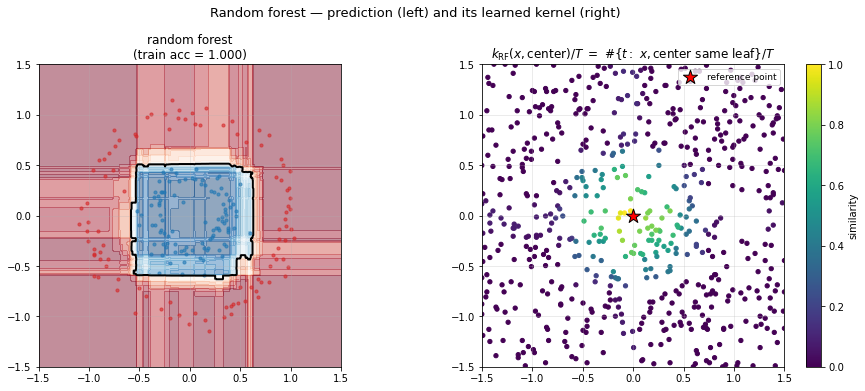

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

rng = np.random.default_rng(0)

# ----------------------------------------------------------------------
# 1. Same rings data as the SVM notebook
# ----------------------------------------------------------------------
def sample_rings(n=200, noise=0.08, r_in=0.4, r_out=1.0):
    n_in = n // 2
    n_out = n - n_in
    t_in  = rng.uniform(0, 2*np.pi, n_in)
    t_out = rng.uniform(0, 2*np.pi, n_out)
    r_i = r_in  + rng.normal(0, noise, n_in)
    r_o = r_out + rng.normal(0, noise, n_out)
    X_in  = np.c_[r_i*np.cos(t_in),  r_i*np.sin(t_in)]
    X_out = np.c_[r_o*np.cos(t_out), r_o*np.sin(t_out)]
    X = np.vstack([X_in, X_out])
    y = np.r_[np.zeros(n_in, int), np.ones(n_out, int)]
    perm = rng.permutation(n)
    return X[perm], y[perm]

X, y = sample_rings()

gx, gy = np.meshgrid(np.linspace(-1.5, 1.5, 300),
                     np.linspace(-1.5, 1.5, 300))
X_test = np.c_[gx.ravel(), gy.ravel()]

# %% [markdown]
# ## Explicit leaf-indicator map
#
# We build a small forest, extract each tree's leaf assignment for any point,
# and assemble the one-hot vector $\phi(x)$ by hand. Then we check that a
# **linear** logistic regression on $\phi(x)$ reproduces the forest's
# predictions to within floating-point error — the numerical proof of the
# "forest = linear model in leaf space" claim.

# %%
# ----------------------------------------------------------------------
# 2. Build a small forest and the explicit leaf-indicator feature map
# ----------------------------------------------------------------------
forest = RandomForestClassifier(n_estimators=25, max_depth=6,
                                random_state=0).fit(X, y)

def leaf_ids(model, X):
    """Column t = leaf index of tree t for every row of X."""
    return np.column_stack([est.apply(X) for est in model.estimators_])

def phi_leaf(model, X):
    """Sparse leaf-indicator feature map phi(x) in R^{total leaves}."""
    L = leaf_ids(model, X)                              # (n, T)
    offset = np.r_[0, np.cumsum([est.tree_.node_count
                                 for est in model.estimators_])[:-1]]
    total  = offset[-1] + model.estimators_[-1].tree_.node_count
    Phi = np.zeros((X.shape[0], total))
    for t in range(L.shape[1]):
        Phi[np.arange(X.shape[0]), offset[t] + L[:, t]] = 1.0
    return Phi

Phi_train = phi_leaf(forest, X)
Phi_test  = phi_leaf(forest, X_test)
print(f"phi(x) has dimension {Phi_train.shape[1]} "
      f"(= total number of leaves across all 25 trees)")

# %% [markdown]
# ### Check: forest ≈ linear model in leaf space
#
# The forest's class probabilities are `predict_proba`. A logistic
# regression on `phi(x)` should learn essentially the same mapping — same
# accuracy, same probability surface. This is the forest's version of
# "$\hat g(x)=\operatorname{sign}(w^\top\phi(x)+b)$".

# %%
# ----------------------------------------------------------------------
# 3. Linear model on phi(x) ≈ forest itself
# ----------------------------------------------------------------------
lr = LogisticRegression(max_iter=5000, C=1e6).fit(Phi_train, y)

forest_pred = forest.predict_proba(X_test)[:, 1]
lr_pred     = lr.predict_proba(Phi_test)[:, 1]

print(f"max |forest_proba - LR_on_phi_proba| = "
      f"{np.abs(forest_pred - lr_pred).max():.3e}")
print(f"train accuracy  forest: {forest.score(X, y):.4f}")
print(f"train accuracy  LR on phi(x): {lr.score(Phi_train, y):.4f}")

# %% [markdown]
# ## The forest as an adaptive kernel
#
# Just as the RBF kernel defines a similarity by *distance*, a random forest
# defines a similarity by **agreement across trees**:
#
# $$
# k_{\text{RF}}(x,x')=\#\{t:\ x,x'\text{ land in the same leaf of tree }t\}.
# $$
#
# We can compute this kernel explicitly on a small grid (500 × 500 is fine)
# and show that:
#
# - it is **positive semi-definite** — so it really is an inner product in
#   some feature space,
# - its "decision boundary" (contour at the median similarity) **wraps
#   around the ring**, unlike a linear kernel,
# - it is **learned** — its shape depends on the forest's splits, not on a
#   hand-chosen formula like the RBF kernel.

# %%
# ----------------------------------------------------------------------
# 4. Forest kernel matrix on a coarse grid and its decision surface
# ----------------------------------------------------------------------
from sklearn.metrics.pairwise import pairwise_kernels

# subsample the grid for a manageable kernel matrix
idx = rng.choice(len(X_test), size=600, replace=False)
G = X_test[idx]

# leaf paths on the subsampled grid: (n, T) integers
Lg = leaf_ids(forest, G)
# kernel: number of trees on which two points share a leaf
K_rf = (Lg[:, None, :] == Lg[None, :, :]).sum(axis=2).astype(float)

print(f"K_rf shape = {K_rf.shape}")
print(f"K_rf min eigenvalue = "
      f"{np.linalg.eigvalsh((K_rf + K_rf.T)/2).min():+.3e}  "
      f"(>= 0 ⇔ PSD)")

# similarity to a reference point inside the inner ring
ref = np.array([0.0, 0.0])
L_ref = leaf_ids(forest, ref[None, :])           # (1, T)
sim_to_center = (Lg == L_ref).sum(axis=1).astype(float)  # (n,)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

# (a) forest decision boundary
ax = axes[0]
Z = forest.predict_proba(X_test)[:, 1].reshape(gx.shape)
ax.contourf(gx, gy, Z, levels=20, cmap="RdBu_r", alpha=0.45)
ax.contour(gx, gy, Z, levels=[0.5], colors="k", linewidths=2)
ax.scatter(X[y==0, 0], X[y==0, 1], s=10, color="C0", alpha=0.6)
ax.scatter(X[y==1, 0], X[y==1, 1], s=10, color="C3", alpha=0.6)
ax.set_title(f"random forest\n(train acc = {forest.score(X, y):.3f})")
ax.set_aspect("equal"); ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.5, 1.5)
ax.grid(alpha=0.3)

# (b) forest kernel similarity to the center of the inner ring
ax = axes[1]
T = len(forest.estimators_)
ax.scatter(G[:, 0], G[:, 1], c=sim_to_center / T, s=18,
           cmap="viridis", vmin=0, vmax=1)
ax.scatter(*ref, marker="*", s=220, color="red",
           edgecolor="k", zorder=5, label="reference point")
ax.set_title(r"$k_{\mathrm{RF}}(x,\mathrm{center})/T$ "
             r"$=\ \#\{t:\ x,\mathrm{center}\ \mathrm{same\ leaf}\}/T$")
ax.set_aspect("equal"); ax.set_xlim(-1.5, 1.5); ax.set_ylim(-1.5, 1.5)
ax.legend(fontsize=9, loc="upper right")
ax.grid(alpha=0.3)
cbar = fig.colorbar(ax.collections[0], ax=ax); cbar.set_label("similarity")

fig.suptitle("Random forest — prediction (left) and its learned kernel (right)",
             fontsize=13)
fig.tight_layout()
plt.show()